In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
dataset = pd.read_csv('Algerian_forest_fires_dataset_Cleaned.csv')
dataset = dataset.drop(['index','day','month','year'],axis=1)

In [3]:
dataset['Classes'] = np.where(dataset['Classes'].str.contains('not fire'),0,1)

In [4]:
dataset['Classes'].value_counts()

Classes
1    137
0    106
Name: count, dtype: int64

In [5]:
dataset.tail()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
238,30,65,14,0.0,85.4,16.0,44.5,4.5,16.9,6.5,1,1
239,28,87,15,4.4,41.1,6.5,8.0,0.1,6.2,0.0,0,1
240,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,0,1
241,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,0,1
242,24,64,15,0.2,67.3,3.8,16.5,1.2,4.8,0.5,0,1


In [6]:
from sklearn.model_selection import train_test_split

X = dataset.drop("FWI",axis=1)
y  = dataset['FWI']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.25,random_state=42)
X_train

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
97,29,74,19,0.1,75.8,3.6,32.2,2.1,5.6,0,0
141,31,72,14,0.2,60.2,3.8,8.0,0.8,3.7,0,1
192,40,31,15,0.0,94.2,22.5,46.3,16.6,22.4,1,1
68,32,60,18,0.3,77.1,11.3,47.0,2.2,14.1,0,0
119,32,47,14,0.7,77.5,7.1,8.8,1.8,6.8,0,0
...,...,...,...,...,...,...,...,...,...,...,...
106,24,82,15,0.4,44.9,0.9,7.3,0.2,1.4,0,0
14,28,80,17,3.1,49.4,3.0,7.4,0.4,3.0,0,0
92,25,76,17,7.2,46.0,1.3,7.5,0.2,1.8,0,0
179,34,59,16,0.0,88.1,19.5,47.2,7.4,19.5,1,1


## FEATURE SELECTION

<Axes: >

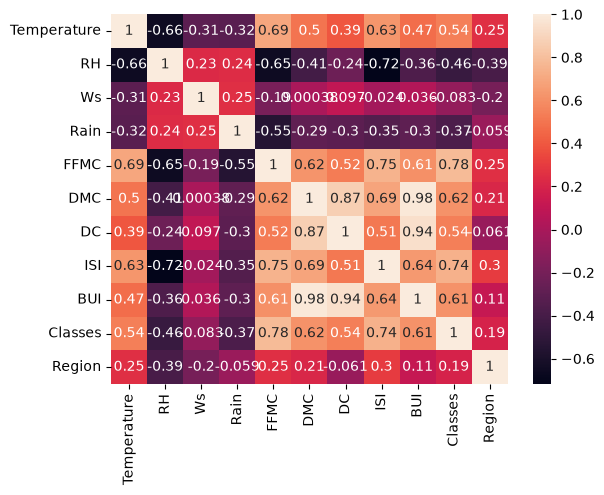

In [7]:
sns.heatmap(X_train.corr(),annot=True)
## in case of multicollinearity  - the independent feature will be highly correlated


In [8]:
def correlation(dataset,threshold):
    columns_set = set()

    corr_matrix  = dataset.corr()
     
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i,j]) > threshold:
                    colname = corr_matrix.columns[i]
                    columns_set.add(colname)
    return columns_set                

In [9]:
corr_features = correlation(X_train,0.85)
corr_features

{'BUI', 'DC'}

In [10]:
X_train.drop(corr_features,axis=1,inplace=True)
X_test.drop(corr_features,axis=1,inplace=True)
X_train

,Temperature,RH,Ws,Rain,FFMC,DMC,ISI,Classes,Region
97,29,74,19,0.1,75.8,3.6,2.1,0,0
141,31,72,14,0.2,60.2,3.8,0.8,0,1
192,40,31,15,0.0,94.2,22.5,16.6,1,1
68,32,60,18,0.3,77.1,11.3,2.2,0,0
119,32,47,14,0.7,77.5,7.1,1.8,0,0
...,...,...,...,...,...,...,...,...,...
106,24,82,15,0.4,44.9,0.9,0.2,0,0
14,28,80,17,3.1,49.4,3.0,0.4,0,0
92,25,76,17,7.2,46.0,1.3,0.2,0,0
179,34,59,16,0.0,88.1,19.5,7.4,1,1


## Standardization

In [11]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)


## Linear Regression

In [12]:
from sklearn.linear_model import LinearRegression

regression = LinearRegression(n_jobs=-1)

regression.fit(X_train_scaled,y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[-0.04,-0.17, 0.01,..., 4.84, 0.4 ,-0.39]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.156
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](9,)","[28.82,14.8 ,13.67,..., 7.68, 5.77, 4.49]"


In [13]:
y_test_pred = regression.predict(X_test_scaled)


In [14]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

score = r2_score(y_test,y_test_pred)
mae = mean_absolute_error(y_test,y_test_pred)
mse = mean_squared_error(y_test,y_test_pred)
print(score,mae,mse)

0.9607056657860652 0.9939450225331379 1.739188563820473


0.9692970913627958 0.9605020166901075 1.3589274038116668


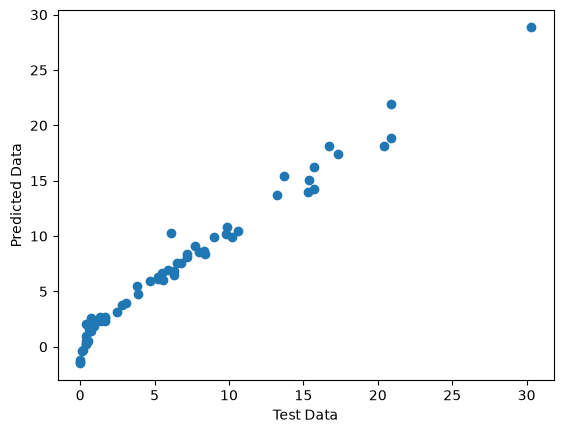

In [15]:
## Lasso Regression
from sklearn.linear_model import Lasso

lasso = Lasso()

lasso.fit(X_train_scaled,y_train)
y_test_pred = lasso.predict(X_test_scaled)

score = r2_score(y_test,y_test_pred)
mae = mean_absolute_error(y_test,y_test_pred)
mse = mean_squared_error(y_test,y_test_pred)
print(score,mae,mse)

plt.scatter(y_test,y_test_pred)
plt.xlabel("Test Data")
plt.ylabel("Predicted Data")
plt.show()




0.9616458508455313 0.9862070802884407 1.6975754626951072


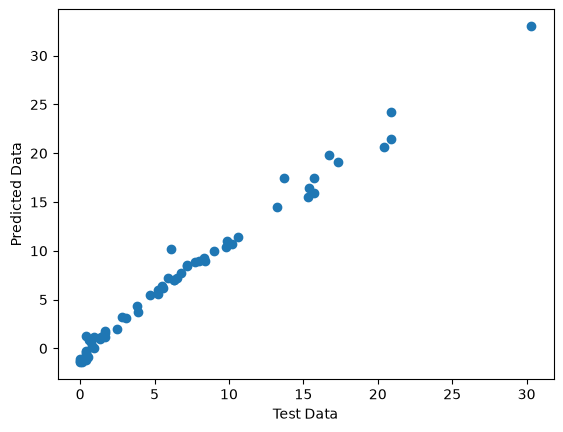

In [16]:
## Ridge Regression
from sklearn.linear_model import Ridge

ridge = Ridge()

ridge.fit(X_train_scaled,y_train)
y_test_pred = ridge.predict(X_test_scaled)

score = r2_score(y_test,y_test_pred)
mae = mean_absolute_error(y_test,y_test_pred)
mse = mean_squared_error(y_test,y_test_pred)
print(score,mae,mse)

plt.scatter(y_test,y_test_pred)
plt.xlabel("Test Data")
plt.ylabel("Predicted Data")
plt.show()

0.9609487032837911 0.9656462022609893 1.728431592234618


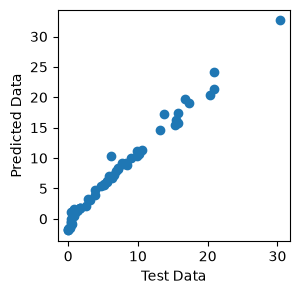

In [28]:
## LassoCV 
from sklearn.linear_model import LassoCV

lassocv = LassoCV(cv=5)

lassocv.fit(X_train_scaled,y_train)
y_test_pred = lassocv.predict(X_test_scaled)

score = r2_score(y_test,y_test_pred)
mae = mean_absolute_error(y_test,y_test_pred)
mse = mean_squared_error(y_test,y_test_pred)
print(score,mae,mse)
plt.figure(figsize=(3,3))
plt.scatter(y_test,y_test_pred)
plt.xlabel("Test Data")
plt.ylabel("Predicted Data")
plt.show()


In [18]:
## RidgeCV
from sklearn.linear_model import RidgeCV

ridgecv = RidgeCV(cv=2)

ridgecv.fit(X_train_scaled,y_train)
y_test_pred = ridgecv.predict(X_test_scaled)

score = r2_score(y_test,y_test_pred)
mae = mean_absolute_error(y_test,y_test_pred)
mse = mean_squared_error(y_test,y_test_pred)
print(score,mae,mse)

# plt.scatter(y_test,y_test_pred)
# plt.xlabel("Test Data")
# plt.ylabel("Predicted Data")
# plt.show()
ridgecv.get_params()

0.9616458508455313 0.9862070802884407 1.6975754626951072


{'alpha_per_target': False,
 'alphas': (0.1, 1.0, 10.0),
 'cv': 2,
 'fit_intercept': True,
 'gcv_mode': None,
 'scoring': None,
 'store_cv_results': False}

0.9081701979826986 1.6511868133560939 4.064436888454822


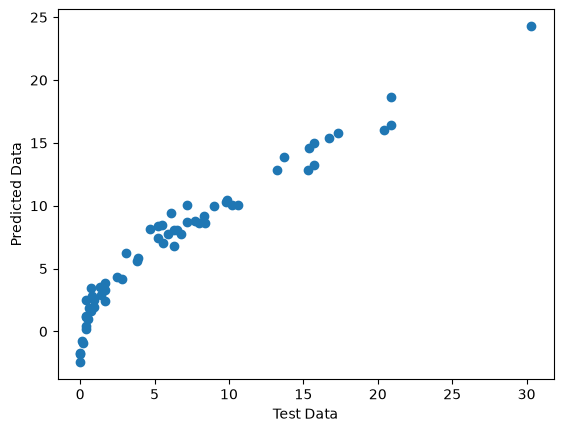

In [19]:
## elastic net
from sklearn.linear_model import ElasticNet

elasticnet = ElasticNet()

elasticnet.fit(X_train_scaled,y_train)
y_test_pred = elasticnet.predict(X_test_scaled)

score = r2_score(y_test,y_test_pred)
mae = mean_absolute_error(y_test,y_test_pred)
mse = mean_squared_error(y_test,y_test_pred)
print(score,mae,mse)

plt.scatter(y_test,y_test_pred)
plt.xlabel("Test Data")
plt.ylabel("Predicted Data")
plt.show()


0.9635664846226284 0.9658446127981593 1.6125671690762837


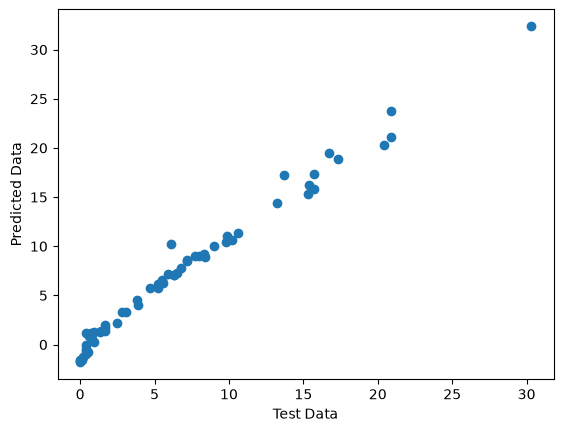

In [20]:
from sklearn.linear_model import ElasticNetCV

elasticnetcv = ElasticNetCV()

elasticnetcv.fit(X_train_scaled,y_train)
y_test_pred = elasticnetcv.predict(X_test_scaled)

score = r2_score(y_test,y_test_pred)
mae = mean_absolute_error(y_test,y_test_pred)
mse = mean_squared_error(y_test,y_test_pred)
print(score,mae,mse)

plt.scatter(y_test,y_test_pred)
plt.xlabel("Test Data")
plt.ylabel("Predicted Data")
plt.show()

In [21]:
## Lasso is having highest accuracy , 2nd) elasticnetcv
## pickle the machine learning model and preprocessing model scaler


In [22]:
import pickle
pickle.dump(scaler,open('scaler.pkl','wb'))
pickle.dump(lasso,open('lasso.pkl','wb'))

In [30]:
features = np.array([[
                29,57,18,0,65,20,5,0,0
            ]])

lasso.predict(scaler.transform(features))[0]

c:\Users\Kavya Gandhi\anaconda3\envs\myenv1\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


np.float64(9.119772821158245)